In [1]:
import pandas as pd
from tabulate import tabulate
import math
import re
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression


In [2]:
df = pd.read_csv('dataset_grupo_08.csv')

In [3]:
# ============================================================
# 2. VARIABLE TYPES
# ============================================================

numeric_cols = df.select_dtypes(include="number").columns
categorical_cols = df.select_dtypes(include="object").columns

print("\n" + "=" * 60)
print("VARIABLE TYPES")
print("=" * 60)

print("\nNumerical variables:")
print(list(numeric_cols))

print("\nCategorical variables:")
print(list(categorical_cols))



VARIABLE TYPES

Numerical variables:
['age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative', 'target_regression']

Categorical variables:
['age_level', 'gender', 'bmi_level', 'smoking', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'sugar_consumption', 'education_level', 'employment_status', 'target_class']


C:\Users\moale\AppData\Local\Temp\ipykernel_31088\2444264265.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns


In [4]:
# Create a copy to preserve the original dataframe
df_encoded = df.copy()

# Identificar as colunas alvo
target_columns = ["target_class", "target_regression"]

# 1. Ordinal encoding
ordinal_mappings = {
    "bmi_level": {
        "Underweight": 1,
        "Normal": 2,
        "Overweight": 3,
        "Obese": 4
    },
    "physical_activity": {
        "Low": 1,
        "Moderate": 2,
        "High": 3
    },
    "stress_level": {
        "Low": 1,
        "Medium": 2,
        "High": 3
    },
    "sugar_consumption": {
        "Low": 1,
        "Medium": 2,
        "High": 3
    }
}

for column, mapping in ordinal_mappings.items():
    df_encoded[column] = df_encoded[column].map(mapping)


# 2. Binary encoding
binary_mappings = {
    "gender": {
        "Male": 0,
        "Female": 1
    },
    "family_history": {
        "No": 0,
        "Yes": 1
    },
    "low_hdl_cholesterol": {
        "No": 0,
        "Yes": 1
    },
    "high_ldl_cholesterol": {
        "No": 0,
        "Yes": 1
    }
}

for column, mapping in binary_mappings.items():
    df_encoded[column] = df_encoded[column].map(mapping)


# 3. One-hot encoding
one_hot_categories = {
    "age_level": ["Young", "Middle", "Mature", "Senior"],
    "smoking": ["Never", "Former", "Current"],
    "education_level": ["Primary", "Secondary", "Tertiary"],
    "employment_status": ["Unemployed", "Employed", "Retired"]
}

for column, categories in one_hot_categories.items():
    df_encoded[column] = pd.Categorical(
        df_encoded[column],
        categories=categories
    )

df_encoded = pd.get_dummies(
    df_encoded,
    columns=list(one_hot_categories.keys()),
    dtype=int
)

# Check the result
display(df_encoded.head(10))
print("Encoded dataset shape:", df_encoded.shape)
display(df_encoded.dtypes.to_frame("Data type"))

# 6. Verificar o resultado
print("Original shape:", df.shape)
print("Encoded shape:", df_encoded.shape)

print("\nColunas finais:")
print(df_encoded.columns.tolist())

# Identificar as colunas que foram codificadas
encoded_columns = (
    list(ordinal_mappings.keys())
    + list(binary_mappings.keys())
    + [
        col
        for col in df_encoded.columns
        if any(
            col.startswith(f"{category}_")
            for category in one_hot_categories
        )
    ]
)

# Manter apenas colunas que existem no DataFrame
encoded_columns = [
    col for col in encoded_columns
    if col in df_encoded.columns
]


print("\nValores nulos nas colunas codificadas:")
print(df_encoded[encoded_columns].isna().sum())

,gender,bmi_level,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,physical_activity,...,age_level_Senior,smoking_Never,smoking_Former,smoking_Current,education_level_Primary,education_level_Secondary,education_level_Tertiary,employment_status_Unemployed,employment_status_Employed,employment_status_Retired
0,0,4,44,0.482758,35.70,5.398540,250.000000,5.300000,235.000000,3,...,0,1,0,0,1,0,0,0,1,0
1,0,4,49,0.540230,34.97,6.500000,224.684501,7.060728,149.460563,2,...,0,0,1,0,0,1,0,1,0,0
2,0,1,4,0.022989,17.64,6.000000,228.130653,7.080402,156.115578,2,...,0,1,0,0,0,0,1,0,1,0
3,0,1,40,0.436781,17.30,5.421429,299.000000,9.500000,150.000000,1,...,0,0,0,1,1,0,0,0,1,0
4,1,2,27,0.287356,24.80,5.374373,277.000000,8.500000,187.000000,3,...,0,0,0,1,0,0,1,0,1,0
5,0,2,44,0.482758,20.60,5.332298,280.000000,5.000000,57.000000,3,...,0,0,0,1,0,1,0,0,0,1
6,1,4,85,0.954022,38.80,5.311429,247.000000,7.200000,212.000000,3,...,1,0,0,1,1,0,0,1,0,0
7,1,4,49,0.540229,33.70,6.950128,264.000000,7.300000,158.000000,1,...,0,0,1,0,0,0,1,1,0,0
8,1,1,29,0.310344,18.40,5.472727,184.000000,9.800000,115.000000,2,...,0,1,0,0,1,0,0,1,0,0
9,0,4,65,0.724137,38.10,5.436598,262.000000,10.000000,223.000000,1,...,0,0,0,1,0,1,0,1,0,0


Encoded dataset shape: (2000, 44)


,Data type
gender,int64
bmi_level,int64
age,int64
age_normalized,float64
bmi,float64
HbA1c_level,float64
cholesterol,float64
sleep_hours,float64
triglycerides,float64
physical_activity,int64


Original shape: (2000, 35)
Encoded shape: (2000, 44)

Colunas finais:
['gender', 'bmi_level', 'age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'blood_pressure', 'sugar_consumption', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative', 'target_regression', 'target_class', 'age_level_Young', 'age_level_Middle', 'age_level_Mature', 'age_level_Senior', 'smoking_Never', 'smoking_Former', 'smoking_Current', 'education_level_Primary', 'education_level_Secondary', 'education_level_Tertiary', 'employment_status_Unemployed', 'employment_status_Employed', 'employment_status_Retired']

Valores nulos nas colunas codificadas:
bmi_level                       0
physical_activity               0
stress_level      

# Simple Linear Regression

In [5]:
df_model = df.copy()

ordinal_mappings = {
    "age_level": {"Young": 0, "Middle": 1, "Mature": 2, "Senior": 3},
    "bmi_level": {"Underweight": 0, "Normal": 1, "Overweight": 2, "Obese": 3},
    "smoking": {"Never": 0, "Former": 1, "Current": 2},
    "physical_activity": {"Low": 0, "Moderate": 1, "High": 2},
    "stress_level": {"Low": 0, "Medium": 1, "High": 2},
    "sugar_consumption": {"Low": 0, "Medium": 1, "High": 2},
    "education_level": {"Primary": 0, "Secondary": 1, "Tertiary": 2},
    "gender": {"Female": 0, "Male": 1},
    "family_history": {"No": 0, "Yes": 1},
}

for col, mapping in ordinal_mappings.items():
    if col in df_model.columns:
        df_model[col] = df_model[col].map(mapping)

df_model = pd.get_dummies(df_model, drop_first=True, dtype=int)

In [14]:
# ============================================================
# 2. DEFINIR PREDITORES (EXCLUIR AMBAS AS TARGETS)
# ============================================================
target_col = "target_regression"

ignore_cols = [target_col, "calcium_baseline"]
if "target_class" in df_model.columns:
    ignore_cols.append("target_class")
else:
    ignore_cols.extend([col for col in df_model.columns if col.startswith("target_class")])

predictors = [col for col in df_model.columns if col not in ignore_cols]

print(f"Número total de preditores a testar: {len(predictors)}")
print(f"Lista de preditores: {predictors}")

Número total de preditores a testar: 33
Lista de preditores: ['age_level', 'gender', 'bmi_level', 'smoking', 'age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'physical_activity', 'family_history', 'stress_level', 'blood_pressure', 'sugar_consumption', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'education_level', 'systolic_index', 'plasma_value', 'ldl_alternative', 'low_hdl_cholesterol_Yes', 'high_ldl_cholesterol_Yes', 'employment_status_Retired', 'employment_status_Unemployed']


In [15]:
# ============================================================
# 3. AVALIAÇÃO DA REGRESSÃO LINEAR SIMPLES
# ============================================================
results = []

for col in predictors:
    X = df_model[[col]].values
    y = df_model[target_col].values

    # Adicionar constante (intercepto beta_0) se usares statsmodels, 
    # ou podes usar a LinearRegression do scikit-learn como tinhas feito antes.
    X_sm = sm.add_constant(X)
    model = sm.OLS(y, X_sm).fit()
    y_pred = model.predict(X_sm)

    # Cálculo das Métricas
    r2 = r2_score(y, y_pred)
    mse = mean_squared_error(y, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y, y_pred)

    slope_coef = model.params[1]
    p_value = model.pvalues[1]

    results.append(
        {
            "Feature": col,
            "R2_Score": r2,
            "RMSE": rmse,
            "MAE": mae,
            "Slope_Beta1": slope_coef,
            "p-value": p_value,
            "Statistically_Significant": "Yes" if p_value < 0.05 else "No",
        }
    )

# Criar DataFrame final ordenado pelo R^2
results_df = (
    pd.DataFrame(results)
    .sort_values(by="R2_Score", ascending=False)
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("RANKING DE PREDITORES - REGRESSÃO LINEAR SIMPLES (TARGET_REGRESSION)")
print("=" * 70)
display(results_df.round(4))


RANKING DE PREDITORES - REGRESSÃO LINEAR SIMPLES (TARGET_REGRESSION)


,Feature,R2_Score,RMSE,MAE,Slope_Beta1,p-value,Statistically_Significant
0,HbA1c_level,0.0126,38.4908,31.9266,4.8733,0.0000,Yes
1,bmi_level,0.0031,38.6746,31.9660,2.1463,0.0121,Yes
2,sleep_hours,0.0023,38.6901,31.9342,1.3898,0.0303,Yes
3,employment_status_Retired,0.0022,38.6923,31.9612,-3.8689,0.0346,Yes
4,bmi,0.0022,38.6933,31.9827,0.2524,0.0366,Yes
5,age_level,0.0016,38.7050,31.9756,1.5214,0.0755,No
6,stress_level,0.0016,38.7054,31.9528,-1.8368,0.0776,No
7,education_level,0.0015,38.7061,31.9715,-1.8141,0.0811,No
8,diastolic_bp,0.0012,38.7128,31.9463,0.1066,0.1246,No
9,high_ldl_cholesterol_Yes,0.0010,38.7160,31.9680,-2.4667,0.1550,No


In [16]:
# ============================================================
# 2. SELEÇÃO DA MELHOR FEATURE COM SCIKIT-LEARN
# ============================================================
y = df_model["target_regression"]
results = []

for col in predictors:
    # Reshape necessário para o scikit-learn (matriz 2D)
    X = df_model[[col]]
    
    model = LinearRegression()
    model.fit(X, y)
    
    y_pred = model.predict(X)
    
    r2 = model.score(X, y)  # r2_score
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    mae = mean_absolute_error(y, y_pred)
    
    results.append({
        "Feature": col,
        "Intercept_beta0": model.intercept_,
        "Slope_beta1": model.coef_[0],
        "R2_Score": r2,
        "RMSE": rmse,
        "MAE": mae
    })

results_df = pd.DataFrame(results).sort_values(by="R2_Score", ascending=False).reset_index(drop=True)

print("=" * 70)
print("RANKING DOS MODELOS DE REGRESSÃO LINEAR SIMPLES")
print("=" * 70)
display(results_df.round(4))

# ============================================================
# 3. DETALHE E EQUAÇÃO DO MELHOR MODELO ENCONTRADO
# ============================================================
best_feature = results_df.loc[0, "Feature"]
best_beta0 = results_df.loc[0, "Intercept_beta0"]
best_beta1 = results_df.loc[0, "Slope_beta1"]
best_r2 = results_df.loc[0, "R2_Score"]

print("\n" + "=" * 70)
print(f"MELHOR PREDITOR SELECIONADO: '{best_feature}'")
print("=" * 70)
print(f"Equação do modelo linear: target_regression = {best_beta0:.4f} + {best_beta1:.4f} * {best_feature}")
print(f"Coeficiente R²: {best_r2:.4f}")

RANKING DOS MODELOS DE REGRESSÃO LINEAR SIMPLES


,Feature,Intercept_beta0,Slope_beta1,R2_Score,RMSE,MAE
0,HbA1c_level,106.4278,4.8733,0.0126,38.4908,31.9266
1,bmi_level,129.9687,2.1463,0.0031,38.6746,31.9660
2,sleep_hours,124.3117,1.3898,0.0023,38.6901,31.9342
3,employment_status_Retired,135.2426,-3.8689,0.0022,38.6923,31.9612
4,bmi,127.0013,0.2524,0.0022,38.6933,31.9827
5,age_level,131.4820,1.5214,0.0016,38.7050,31.9756
6,stress_level,135.8873,-1.8368,0.0016,38.7054,31.9528
7,education_level,135.8995,-1.8141,0.0015,38.7061,31.9715
8,diastolic_bp,124.4489,0.1066,0.0012,38.7128,31.9463
9,high_ldl_cholesterol_Yes,135.2182,-2.4667,0.0010,38.7160,31.9680



MELHOR PREDITOR SELECIONADO: 'HbA1c_level'
Equação do modelo linear: target_regression = 106.4278 + 4.8733 * HbA1c_level
Coeficiente R²: 0.0126


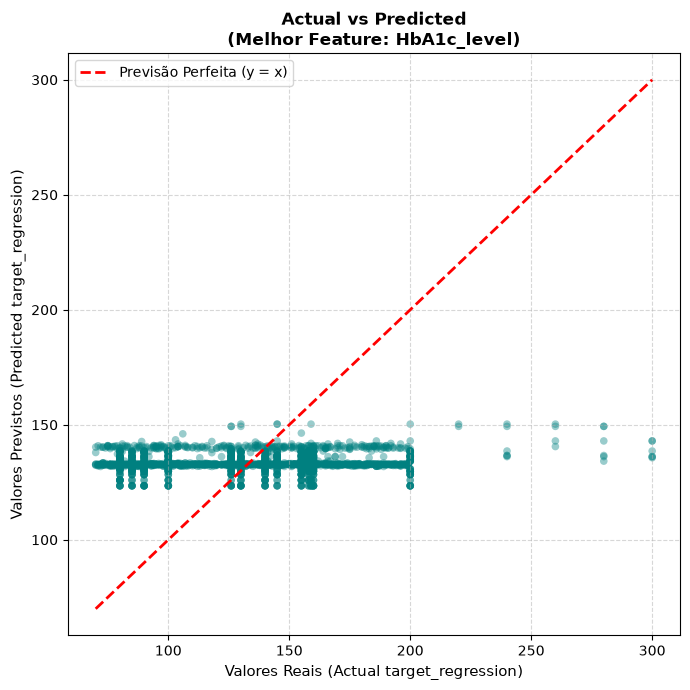

In [17]:
# Garantir que usas a melhor feature encontrada no ranking anterior
best_feature = results_df.loc[0, "Feature"]

X_best = df_model[[best_feature]]
y_true = df_model[target_col]

# Treinar o modelo com a melhor feature
reg_model = LinearRegression()
reg_model.fit(X_best, y_true)
y_pred = reg_model.predict(X_best)

# Criar o gráfico Actual vs Predicted
plt.figure(figsize=(7, 7))
plt.scatter(y_true, y_pred, alpha=0.4, color="teal", edgecolor="none", s=30)

# Desenhar a linha diagonal perfeita (y = x)
min_val = min(y_true.min(), y_pred.min())
max_val = max(y_true.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=2, label="Previsão Perfeita (y = x)")

plt.title(f"Actual vs Predicted\n(Melhor Feature: {best_feature})", fontsize=12, fontweight="bold")
plt.xlabel("Valores Reais (Actual target_regression)", fontsize=11)
plt.ylabel("Valores Previstos (Predicted target_regression)", fontsize=11)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()